# Capstone Milestone One — Week 4: Logistic Regression and Feature Scaling

**Kumar Gaurav · DX799 O1 Data Science Capstone**

## Project Overview

Consumer credit risk is a central concern for lenders because mispriced loans and misjudged credit limits translate directly into losses and lost customers.

In this analysis, I switch from explaining lender decisions (interest rate and credit limit) to the binary question itself: can borrower information predict whether a loan or credit-card account will default? The analysis uses logistic regression as the main model, with feature scaling, class weighting, cross-validated regularization tuning, and threshold selection applied on top.

### Research Question

Can borrower characteristics predict default on a closed consumer credit account, and what role do feature scaling, class weighting, and threshold choice play in producing a usable decision rule when the positive class is a minority?

The two target variables used here are both binary:

* **Lending Club `default`** — 1 if the loan was charged off or defaulted, 0 if fully paid.
* **Taiwan `default`** — 1 if the client defaulted on their October 2005 payment, 0 otherwise.

### Objectives

The objectives of this analysis are to:

* Fit a baseline logistic regression on Lending Club and compare unscaled, standardized, and min–max scaled numerics.
* Use `class_weight="balanced"` to repair the recall collapse that occurs at the default 0.5 threshold with a 20% positive class.
* Tune the regularization strength `C` and penalty (L1/L2) with 5-fold stratified `GridSearchCV` on ROC-AUC.
* Choose the decision threshold on out-of-fold training predictions and apply it to the held-out test set.
* Repeat the modeling on the Taiwan dataset and compare the fitted odds ratios across the two markets.

### Approach

The analysis follows a two-part modeling structure:

Baseline Logistic Regression and Feature Scaling (Lending Club) → Class Weights, CV Tuning, Threshold Choice (both datasets) → Summary

### Datasets

* **Lending Club** (Kaggle `adarshsng/lending-club-loan-data-csv`): US peer-to-peer installment loans, 2007–2018.
* **UCI Default of Credit Card Clients** (Yeh & Lien, 2009; Kaggle `uciml/default-of-credit-card-clients-dataset`): 30,000 Taiwanese credit-card clients, April–September 2005, with a target of default in October 2005.

## 1. Data Loading and Cleaning

The code cells below load the two raw files, apply the documented cleaning rules (outcome definition, invalid-range handling, undocumented-code recoding, log transforms, and target-leakage removal), and produce the cleaned `lc` and `tw` frames that the modeling sections use. The data-quality audit for these datasets is documented separately.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                               f1_score, roc_auc_score, confusion_matrix, roc_curve)

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

# Lending Club loan data — binary default prediction task
path = kagglehub.dataset_download("adarshsng/lending-club-loan-data-csv/versions/1")
csv_path = os.path.join(path, "loan.csv")

USECOLS = ['loan_status', 'loan_amnt', 'term', 'int_rate', 'grade',
           'home_ownership', 'annual_inc', 'dti', 'purpose',
           'verification_status', 'open_acc', 'revol_util']
CLOSED = ['Fully Paid', 'Charged Off', 'Default']

chunks = []
for ch in pd.read_csv(csv_path, usecols=USECOLS, chunksize=500000, low_memory=True):
    chunks.append(ch[ch['loan_status'].isin(CLOSED)])
df = pd.concat(chunks, ignore_index=True)

print(f"Closed-loan shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
display(df['loan_status'].value_counts().rename_axis('loan_status').to_frame(name='count'))
display(df.head(3))


Libraries imported successfully.
Closed-loan shape: (1303638, 12)
Columns: ['loan_amnt', 'term', 'int_rate', 'grade', 'home_ownership', 'annual_inc', 'verification_status', 'loan_status', 'purpose', 'dti', 'open_acc', 'revol_util']


,count
loan_status,
Fully Paid,1041952
Charged Off,261655
Default,31


,loan_amnt,term,int_rate,grade,home_ownership,annual_inc,verification_status,loan_status,purpose,dti,open_acc,revol_util
0,30000,36 months,22.35,D,MORTGAGE,100000.0,Source Verified,Fully Paid,debt_consolidation,30.46,11.0,37.0
1,40000,60 months,16.14,C,MORTGAGE,45000.0,Verified,Fully Paid,credit_card,50.53,18.0,64.5
2,20000,36 months,7.56,A,MORTGAGE,100000.0,Not Verified,Fully Paid,credit_card,18.92,9.0,29.9


In [2]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import kagglehub
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
SEED = 42

# Lending Club: read only the columns we audit/model (the raw file is 2.26M x 145)
LC_PATH = os.path.join(kagglehub.dataset_download("adarshsng/lending-club-loan-data-csv/versions/1"), "loan.csv")
LC_COLS = ["id", "loan_status", "loan_amnt", "term", "int_rate", "grade", "sub_grade", "emp_length",
           "home_ownership", "annual_inc", "verification_status", "purpose", "dti", "delinq_2yrs",
           "inq_last_6mths", "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc", "mort_acc",
           "pub_rec_bankruptcies", "application_type", "policy_code",
           # post-outcome columns, loaded ONLY to demonstrate the leakage screen
           "total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"]
lc_raw = pd.read_csv(LC_PATH, usecols=LC_COLS, low_memory=False)
print(f"Lending Club raw shape (audited columns): {lc_raw.shape}")
print(lc_raw.dtypes.value_counts().to_string())
display(lc_raw.head(3))

Lending Club raw shape (audited columns): (2260668, 28)
float64    16
str         9
int64       3


,id,loan_amnt,term,int_rate,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,...,revol_util,total_acc,out_prncp,total_pymnt,recoveries,last_pymnt_amnt,policy_code,application_type,mort_acc,pub_rec_bankruptcies
0,NaN,2500,36 months,13.56,C,C1,10+ years,RENT,55000.0,Not Verified,...,10.3,34.0,2386.02,167.02,0.0,84.92,1,Individual,0.0,1.0
1,NaN,30000,60 months,18.94,D,D2,10+ years,MORTGAGE,90000.0,Source Verified,...,24.2,44.0,29387.75,1507.11,0.0,777.23,1,Individual,3.0,1.0
2,NaN,5000,36 months,17.97,D,D1,6 years,MORTGAGE,59280.0,Source Verified,...,19.1,13.0,4787.21,353.89,0.0,180.69,1,Individual,2.0,0.0


In [4]:
# Keep closed loans only (outcome known); 'Current'/'Late' loans are censored
CLOSED = ["Fully Paid", "Charged Off", "Default"]
print("loan_status counts:"); print(lc_raw["loan_status"].value_counts().to_string())
lc = lc_raw[lc_raw["loan_status"].isin(CLOSED)].copy()
print(f"\nClosed loans: {len(lc):,}")

dq = []  # (issue, rows affected, action)
dq.append(("Open/censored loan_status", len(lc_raw) - len(lc), "dropped (outcome unknown)"))
dq.append(("id column 100% null", 0, "cannot dedupe on id; deduped on full row instead"))
dups = lc.drop(columns=["id"]).duplicated().sum(); dq.append(("Exact duplicate rows", dups, "dropped"))
lc = lc.drop(columns=["id"]).drop_duplicates()

# Invalid / impossible ranges
bad_dti = ((lc["dti"] < 0) | (lc["dti"] > 100)).sum()
dq.append(("dti < 0 or > 100% (sentinel 999 / data error)", bad_dti, "set to NaN then dropped"))
lc.loc[(lc["dti"] < 0) | (lc["dti"] > 100), "dti"] = np.nan
hi_util = (lc["revol_util"] > 100).sum()
dq.append(("revol_util > 100%", hi_util, "clipped to 150 (over-limit is real but extreme)"))
lc["revol_util"] = lc["revol_util"].clip(upper=150)
zero_inc = (lc["annual_inc"] <= 0).sum()
dq.append(("annual_inc <= 0", zero_inc, "dropped (cannot log/ratio)"))
lc = lc[lc["annual_inc"] > 0]
hi_inc = (lc["annual_inc"] > 1e6).sum()
dq.append(("annual_inc > $1M", hi_inc, "kept; modeled as log1p(annual_inc)"))
odd_home = lc["home_ownership"].isin(["ANY", "NONE", "OTHER"]).sum()
dq.append(("home_ownership ANY/NONE/OTHER", odd_home, "merged into OTHER"))
lc["home_ownership"] = lc["home_ownership"].replace({"ANY": "OTHER", "NONE": "OTHER"})

# Constant / near-constant and cardinality
const = [c for c in lc.columns if lc[c].nunique(dropna=False) <= 1]
print("Constant columns:", const)
dq.append(("Constant columns " + str(const), 0, "column dropped (no information)"))
lc = lc.drop(columns=const)
cat_cols = lc.select_dtypes("object").columns
print("Categorical cardinality:", lc[cat_cols].nunique().to_dict())

# Leakage screen: columns only known AFTER the outcome
LEAK = ["total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"]
print("\nLeakage check: mean of post-outcome columns by outcome")
print(lc.groupby(lc["loan_status"] != "Fully Paid")[LEAK].mean().round(1).rename(index={False: "repaid", True: "default"}).to_string())
dq.append(("Post-outcome columns " + ", ".join(LEAK), 0, "columns dropped (target leakage)"))
lc = lc.drop(columns=LEAK)

lc["default"] = (lc["loan_status"] != "Fully Paid").astype(int)
before = len(lc)
lc = lc.dropna(subset=["dti", "revol_util", "mort_acc", "pub_rec_bankruptcies", "inq_last_6mths", "open_acc", "total_acc"])
dq.append(("Remaining NaNs in model columns", before - len(lc), "dropped (listwise)"))
lc["log_annual_inc"] = np.log1p(lc["annual_inc"]); lc["log_revol_bal"] = np.log1p(lc["revol_bal"])
lc["term_months"] = lc["term"].str.extract(r"(\d+)").astype(int)
print(f"\nClean Lending Club rows: {len(lc):,} | default rate: {lc['default'].mean():.2%}")

loan_status counts:
loan_status
Fully Paid                                             1041952
Current                                                 919695
Charged Off                                             261655
Late (31-120 days)                                       21897
In Grace Period                                           8952
Late (16-30 days)                                         3737
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     31

Closed loans: 1,303,638


Constant columns: ['policy_code']
Categorical cardinality: {'term': 2, 'grade': 7, 'sub_grade': 35, 'emp_length': 11, 'home_ownership': 4, 'verification_status': 3, 'loan_status': 3, 'purpose': 14, 'application_type': 2}

Leakage check: mean of post-outcome columns by outcome
             total_pymnt  recoveries  last_pymnt_amnt  out_prncp
loan_status                                                     
repaid           16439.4         0.0           6720.8        0.0
default           8228.0      1173.9            472.6        1.3



Clean Lending Club rows: 1,254,818 | default rate: 20.28%


In [6]:
TW_PATH = os.path.join(kagglehub.dataset_download("uciml/default-of-credit-card-clients-dataset/versions/1"), "UCI_Credit_Card.csv")
tw_raw = pd.read_csv(TW_PATH)
print(f"Taiwan raw shape: {tw_raw.shape}")
print(tw_raw.dtypes.value_counts().to_string())
display(tw_raw.head(3))

Taiwan raw shape: (30000, 25)
float64    13
int64      12


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0


In [7]:
tw = tw_raw.rename(columns={"default.payment.next.month": "default", "PAY_0": "PAY_1"}).copy()
PAY = [f"PAY_{i}" for i in range(1, 7)]; BILL = [f"BILL_AMT{i}" for i in range(1, 7)]; PAMT = [f"PAY_AMT{i}" for i in range(1, 7)]
tdq = []
print("Null cells total:", int(tw.isnull().sum().sum()))
tdq.append(("Missing values", int(tw.isnull().sum().sum()), "none to handle"))
tdq.append(("Duplicate ID", int(tw["ID"].duplicated().sum()), "none"))
dup = int(tw.drop(columns="ID").duplicated().sum())
tdq.append(("Duplicate rows (ignoring ID)", dup, "dropped (identical profiles)"))
tw = tw.loc[~tw.drop(columns="ID").duplicated()].copy()

print("EDUCATION codes:", tw["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE codes:", tw["MARRIAGE"].value_counts().sort_index().to_dict())
print("PAY_1 codes:", tw["PAY_1"].value_counts().sort_index().to_dict())
edu_bad = int(tw["EDUCATION"].isin([0, 5, 6]).sum())
tdq.append(("EDUCATION undocumented codes 0/5/6", edu_bad, "recoded to 4 = other"))
tw["EDUCATION"] = tw["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
mar_bad = int((tw["MARRIAGE"] == 0).sum())
tdq.append(("MARRIAGE undocumented code 0", mar_bad, "recoded to 3 = other"))
tw["MARRIAGE"] = tw["MARRIAGE"].replace({0: 3})
pay_m2 = int((tw[PAY] == -2).any(axis=1).sum())
tdq.append(("PAY_* = -2 (no consumption, undocumented)", pay_m2, "kept as ordinal (-2 < -1 paid duly < 0 revolving)"))
neg_bill = int((tw[BILL] < 0).any(axis=1).sum())
tdq.append(("Negative BILL_AMT (credit balance/overpay)", neg_bill, "kept; signed log transform"))
tdq.append(("AGE range " + f"{tw['AGE'].min()}-{tw['AGE'].max()}", 0, "plausible, kept"))
const = [c for c in tw.columns if tw[c].nunique() <= 1]; tdq.append(("Constant columns", len(const), "none"))

# Leakage screen: all features are observed BEFORE the default month (Apr-Sep 2005 -> Oct 2005)
tdq.append(("Post-outcome columns", 0, "none: all features precede target month"))
slog = lambda s: np.sign(s) * np.log1p(np.abs(s))
for c in BILL + PAMT: tw["log_" + c] = slog(tw[c])
tw["log_LIMIT_BAL"] = np.log(tw["LIMIT_BAL"])
tw = tw.drop(columns="ID")
print(f"\nClean Taiwan rows: {len(tw):,} | default rate: {tw['default'].mean():.2%}")

Null cells total: 0
EDUCATION codes: {0: 14, 1: 10563, 2: 14019, 3: 4915, 4: 123, 5: 280, 6: 51}
MARRIAGE codes: {0: 54, 1: 13643, 2: 15945, 3: 323}
PAY_1 codes: {-2: 2750, -1: 5682, 0: 14737, 1: 3667, 2: 2666, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}

Clean Taiwan rows: 29,965 | default rate: 22.13%


## Part B — Baseline Logistic Regression and Feature Scaling (Lending Club)

With Lending Club cleaned, Part B fits a baseline logistic regression on a 60,000-loan sample and compares unscaled, standardized, and min–max scaled numerics. The target is binary default (1 = Charged Off or Default, 0 = Fully Paid).

The sequence of steps below is:

1. Build the modeling frame — define the binary target, parse `term`, drop missing values, and inspect the modeling features.
2. Split 80/20 stratified on `default` and fit a baseline logistic model on **unscaled** numerics.
3. Fit `StandardScaler` and `MinMaxScaler` on the training numerics only, and inspect the pre- and post-scaling statistics.
4. Compare unscaled, standardized, and min–max scaled fits on the test set, and extract odds ratios from the standardized model.
5. Summarize the results and draw the diagnostic plots (class balance, ROC curves, confusion matrix, top odds ratios).

An explicit decision threshold (`THRESHOLD = 0.50`) is used throughout rather than relying on sklearn's hidden default, so the threshold is visible and tunable later.

In [20]:
# Binary target: 1 = default (Charged Off / Default), 0 = repaid (Fully Paid)
df['default'] = df['loan_status'].isin(['Charged Off', 'Default']).astype(int)

# Parse term '36 months' -> 36 (kept as string for one-hot later; numeric copy for inspection)
df['term_months'] = df['term'].str.extract(r'(\d+)').astype(int)

# Keep only modeling columns and drop rows with missing values
df_model = df.dropna(subset=USECOLS).copy().reset_index(drop=True)

print(f"Rows after cleaning: {len(df_model):,}")
print(f"Default rate: {df_model['default'].mean():.4%} ({df_model['default'].sum():,} defaults)")
display(df_model['term'].value_counts().rename_axis('term').to_frame(name='count'))
display(df_model[['loan_amnt', 'int_rate', 'annual_inc', 'dti', 'open_acc', 'revol_util']].describe().round(2))
feature_desc = pd.DataFrame({
    "feature": ["loan_amnt", "int_rate", "annual_inc", "dti", "open_acc", "revol_util"],
    "description": [
        "Principal loan amount requested by the borrower.",
        "Interest rate on the loan, expressed as a percentage.",
        "Borrower's annual income in dollars.",
        "Debt-to-income ratio, measuring monthly debt obligations relative to income.",
        "Number of open credit accounts.",
        "Revolving credit utilization rate, expressed as a percentage of the credit limit used."
    ]
})
pd.set_option("display.max_colwidth", 200)
display(feature_desc)

Rows after cleaning: 1,302,516
Default rate: 20.0732% (261,456 defaults)


,count
term,
36 months,987934
60 months,314582


,loan_amnt,int_rate,annual_inc,dti,open_acc,revol_util
count,1302516.00,1302516.00,1302516.00,1302516.00,1302516.00,1302516.00
mean,14417.84,13.26,76164.24,18.26,11.60,51.91
std,8697.92,4.76,69982.80,10.94,5.46,24.50
min,500.00,5.31,16.00,-1.00,1.00,0.00
25%,8000.00,9.75,45953.00,11.79,8.00,33.60
50%,12000.00,12.74,65000.00,17.61,11.00,52.30
75%,20000.00,15.99,90000.00,24.04,14.00,70.80
max,40000.00,30.99,10999200.00,999.00,90.00,892.30


,feature,description
0,loan_amnt,Principal loan amount requested by the borrower.
1,int_rate,"Interest rate on the loan, expressed as a percentage."
2,annual_inc,Borrower's annual income in dollars.
3,dti,"Debt-to-income ratio, measuring monthly debt obligations relative to income."
4,open_acc,Number of open credit accounts.
5,revol_util,"Revolving credit utilization rate, expressed as a percentage of the credit limit used."


In [21]:
NUM = ['loan_amnt', 'int_rate', 'annual_inc', 'dti', 'open_acc', 'revol_util']
CAT = ['term', 'grade', 'home_ownership', 'purpose', 'verification_status']

# Fixed 60k sample keeps runtime peer-review friendly and reproducible
dfs = df_model.sample(n=min(60000, len(df_model)), random_state=42).reset_index(drop=True)
X = dfs[NUM + CAT]
y = dfs['default']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
print(f"Train: {X_train.shape}, Test: {X_test.shape}, test default rate: {y_test.mean():.2%}")
# Explicit decision threshold: predict default when P(default) >= THRESHOLD.
# sklearn .predict() hides this as 0.5; we set it ourselves so it is visible and tunable.
THRESHOLD = 0.50
print(f"Decision threshold THRESHOLD = {THRESHOLD} (explicit, not a hidden default)")
prep_unscaled = ColumnTransformer([
    ('num', 'passthrough', NUM),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), CAT),
])
base_pipe = Pipeline([
    ('prep', prep_unscaled),
    ('clf', LogisticRegression(max_iter=1000)),
])
base_pipe.fit(X_train, y_train)
base_prob = base_pipe.predict_proba(X_test)[:, 1]
base_pred = (base_prob >= THRESHOLD).astype(int)  # explicit 0.50 cutoff

print(f"Unscaled: acc={accuracy_score(y_test, base_pred):.4f} "
      f"prec={precision_score(y_test, base_pred):.4f} "
      f"rec={recall_score(y_test, base_pred):.4f} "
      f"f1={f1_score(y_test, base_pred):.4f} "
      f"auc={roc_auc_score(y_test, base_prob):.4f} "
      f"n_iter={base_pipe.named_steps['clf'].n_iter_}")
print("Confusion matrix [TN FP / FN TP]:")
cm_base = confusion_matrix(y_test, base_pred)
display(pd.DataFrame(cm_base, index=['actual repaid', 'actual default'], columns=['pred repaid', 'pred default']))


Train: (48000, 11), Test: (12000, 11), test default rate: 20.14%
Decision threshold THRESHOLD = 0.5 (explicit, not a hidden default)
Unscaled: acc=0.7968 prec=0.4703 rec=0.0687 f1=0.1199 auc=0.6906 n_iter=[1000]
Confusion matrix [TN FP / FN TP]:


,pred repaid,pred default
actual repaid,9396,187
actual default,2251,166


In [22]:
# Fit scalers on TRAIN numerics only (no leakage)
std_scaler = StandardScaler().fit(X_train[NUM])
mm_scaler = MinMaxScaler().fit(X_train[NUM])

print("Before scaling (train means):")
train_means = X_train[NUM].mean().round(2).to_frame(name="mean")
display(train_means)
print("\nAfter StandardScaler (train means ~ 0, stds ~ 1):")
scaled_train = pd.DataFrame(std_scaler.transform(X_train[NUM]), columns=NUM)
summary = pd.DataFrame({
    "mean": scaled_train.mean(),
    "std": scaled_train.std()
}).round(4)
display(summary)
print("\nAfter MinMaxScaler (train min/max):")
mm_tr = pd.DataFrame(mm_scaler.transform(X_train[NUM]), columns=NUM)

min_max_summary = pd.DataFrame({
    "min": mm_tr.min().round(4),
    "max": mm_tr.max().round(4)
})

display(min_max_summary)

Before scaling (train means):


,mean
loan_amnt,14434.23
int_rate,13.23
annual_inc,75815.03
dti,18.20
open_acc,11.61
revol_util,51.86



After StandardScaler (train means ~ 0, stds ~ 1):


,mean,std
loan_amnt,-0.0,1.0
int_rate,0.0,1.0
annual_inc,0.0,1.0
dti,-0.0,1.0
open_acc,-0.0,1.0
revol_util,-0.0,1.0



After MinMaxScaler (train min/max):


,min,max
loan_amnt,0.0,1.0
int_rate,0.0,1.0
annual_inc,0.0,1.0
dti,0.0,1.0
open_acc,0.0,1.0
revol_util,0.0,1.0


In [23]:
def build_pipe(scaler):
    num_step = scaler if scaler is not None else 'passthrough'
    prep = ColumnTransformer([
        ('num', num_step, NUM),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), CAT),
    ])
    return Pipeline([('prep', prep), ('clf', LogisticRegression(max_iter=1000))])

results = {}
probs = {}
iters = {}
for name, scaler in [('unscaled', None), ('standard', StandardScaler()), ('minmax', MinMaxScaler())]:
    pipe = build_pipe(scaler)
    pipe.fit(X_train, y_train)
    prob = pipe.predict_proba(X_test)[:, 1]
    pred = (prob >= THRESHOLD).astype(int)  # same explicit cutoff as Cell 3
    probs[name] = prob
    iters[name] = pipe.named_steps['clf'].n_iter_[0]
    results[name] = {
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred),
        'recall': recall_score(y_test, pred),
        'f1': f1_score(y_test, pred),
        'roc_auc': roc_auc_score(y_test, prob),
        'n_iter': iters[name],
    }
    if name == 'standard':
        std_pipe = pipe

display(pd.DataFrame(results).T.round(4))

# Odds ratios from the standardized model (1-SD change, comparable across numerics)
feat_names = std_pipe.named_steps['prep'].get_feature_names_out()
coefs = std_pipe.named_steps['clf'].coef_[0]
odds = pd.DataFrame({'feature': feat_names, 'coef': coefs, 'odds_ratio': np.exp(coefs)})
odds['effect'] = np.where(odds['odds_ratio'] > 1, 'higher default odds', 'lower default odds')
print("\nTop 5 positive (higher default odds):")
display(odds.sort_values('odds_ratio', ascending=False).head(5).round(4))
print("\nTop 5 negative (lower default odds):")
display(odds.sort_values('odds_ratio').head(5).round(4))


,accuracy,precision,recall,f1,roc_auc,n_iter
unscaled,0.7968,0.4703,0.0687,0.1199,0.6906,1000.0
standard,0.7982,0.4901,0.0513,0.0929,0.6998,55.0
minmax,0.7986,0.5000,0.0451,0.0827,0.6993,61.0



Top 5 positive (higher default odds):


,feature,coef,odds_ratio,effect
12,cat__grade_G,1.3438,3.8335,higher default odds
11,cat__grade_F,1.2454,3.4744,higher default odds
10,cat__grade_E,1.2067,3.3426,higher default odds
9,cat__grade_D,1.1232,3.0747,higher default odds
8,cat__grade_C,0.8745,2.3977,higher default odds



Top 5 negative (lower default odds):


,feature,coef,odds_ratio,effect
13,cat__home_ownership_MORTGAGE,-0.7578,0.4687,lower default odds
16,cat__home_ownership_OWN,-0.4738,0.6226,lower default odds
30,cat__purpose_wedding,-0.4019,0.6691,lower default odds
22,cat__purpose_house,-0.3947,0.6739,lower default odds
17,cat__home_ownership_RENT,-0.3611,0.6969,lower default odds


DATASET RESULTS
Closed loans after cleaning: 1,302,516
Analysis sample: 60,000 (seed 42), train 48,000 / test 12,000
Default rate overall: 20.07%, test: 20.14%

MODEL RESULTS (test set)


,accuracy,precision,recall,f1,roc_auc,n_iter
unscaled,0.7968,0.4703,0.0687,0.1199,0.6906,1000.0
standard,0.7982,0.4901,0.0513,0.0929,0.6998,55.0
minmax,0.7986,0.5000,0.0451,0.0827,0.6993,61.0



Optimizer iterations: {'unscaled': 1000, 'standard': 55, 'minmax': 61}
(unscaled hitting max_iter=1000 means it did NOT converge; scaled converges in ~50-60.)


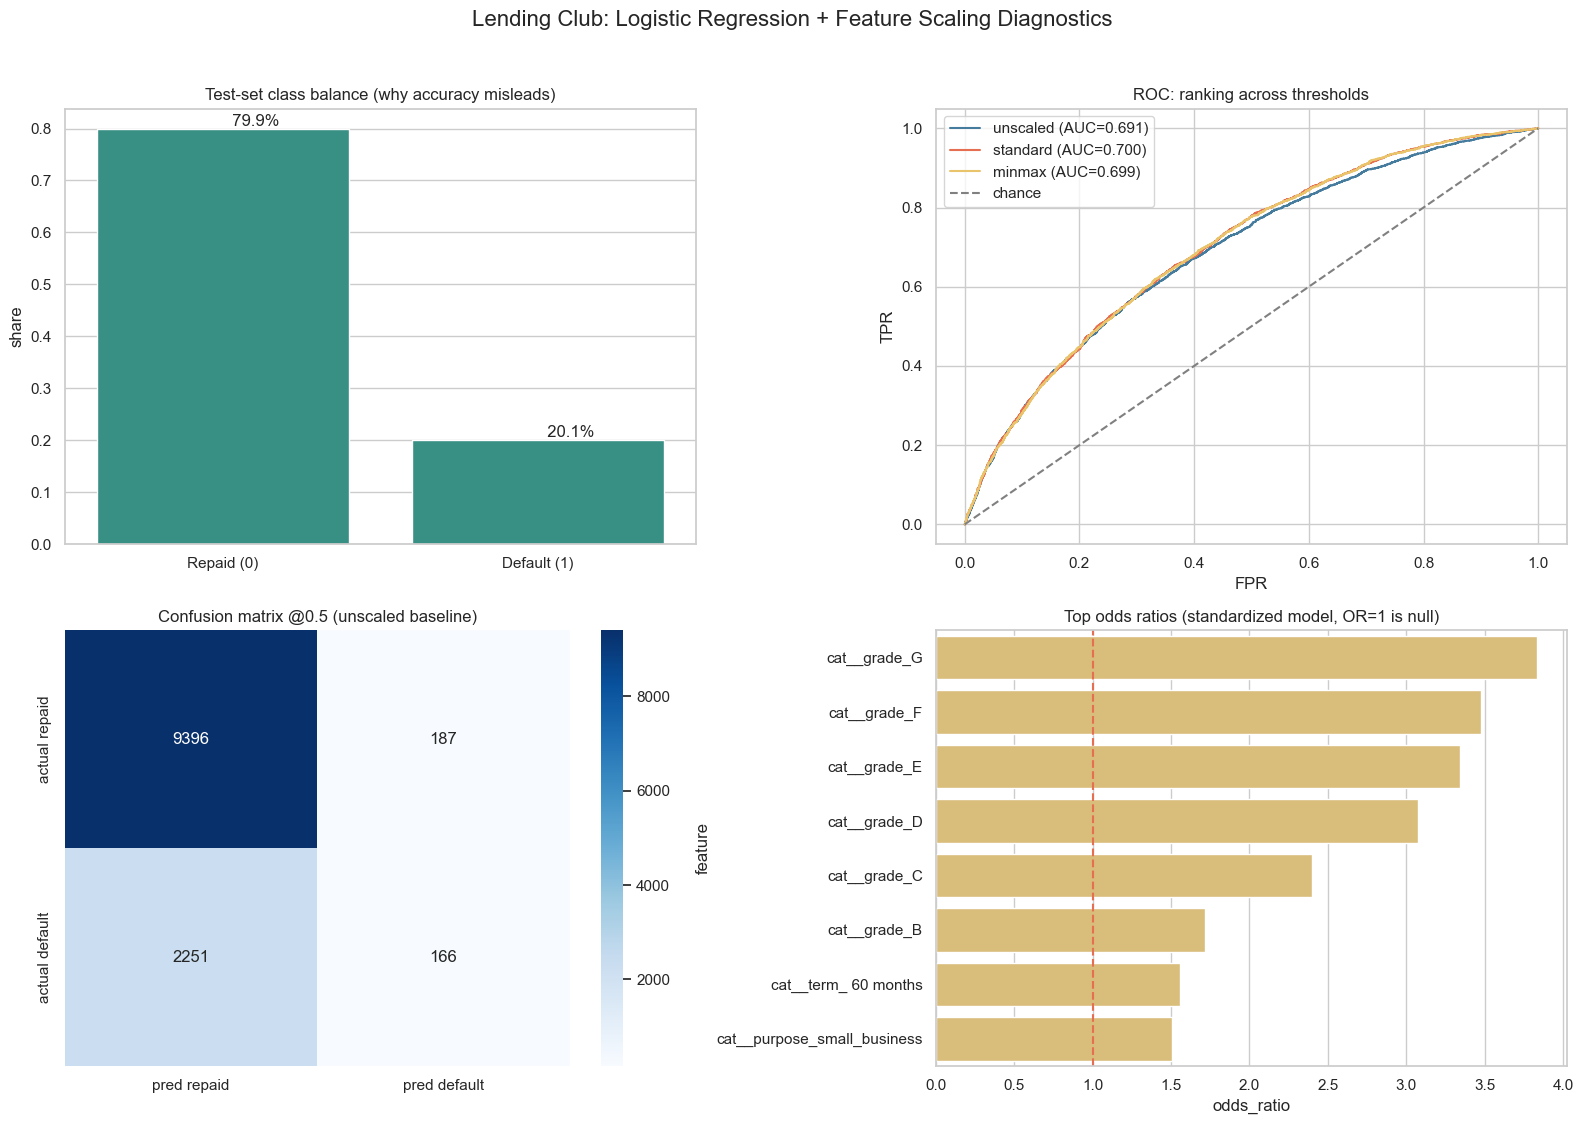


VISUAL INTERPRETATION GUIDE
- Class balance near 80/20: predicting all-repaid gives ~80% accuracy, so judge by precision/recall/F1/AUC.
- ROC curves: overlapping curves mean similar ranking; the scaling win here is convergence (n_iter), not AUC.
- Confusion matrix: low recall means most defaults are missed at 0.5 — threshold tuning or class_weight are follow-ups.
- Odds ratios: OR>1 = higher default odds holding others constant (association, not causation).


In [24]:
print("DATASET RESULTS")
print(f"Closed loans after cleaning: {len(df_model):,}")
print(f"Analysis sample: {len(dfs):,} (seed 42), train {len(X_train):,} / test {len(X_test):,}")
print(f"Default rate overall: {df_model['default'].mean():.2%}, test: {y_test.mean():.2%}")
print("\nMODEL RESULTS (test set)")
display(pd.DataFrame(results).T.round(4))
print(f"\nOptimizer iterations: {iters}")
print("(unscaled hitting max_iter=1000 means it did NOT converge; scaled converges in ~50-60.)")

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("Lending Club: Logistic Regression + Feature Scaling Diagnostics", fontsize=16, y=1.02)

# (a) class balance
ax = axes[0, 0]
sns.barplot(x=['Repaid (0)', 'Default (1)'], y=[1 - y_test.mean(), y_test.mean()], color="#2a9d8f", ax=ax)
ax.set_title("Test-set class balance (why accuracy misleads)")
ax.set_ylabel("share")
for i, v in enumerate([1 - y_test.mean(), y_test.mean()]):
    ax.text(i, v, f"  {v:.1%}", va="bottom")

# (b) ROC curves
ax = axes[0, 1]
for name, color in [('unscaled', '#457b9d'), ('standard', '#e76f51'), ('minmax', '#e9c46a')]:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    ax.plot(fpr, tpr, label=f"{name} (AUC={results[name]['roc_auc']:.3f})", color=color)
ax.plot([0, 1], [0, 1], '--', color='gray', label='chance')
ax.set_title("ROC: ranking across thresholds")
ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend()

# (c) confusion matrices at 0.5
ax = axes[1, 0]
base_test_prob = base_pipe.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, (base_test_prob >= THRESHOLD).astype(int))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['pred repaid', 'pred default'], yticklabels=['actual repaid', 'actual default'])
ax.set_title(f"Confusion matrix @{THRESHOLD} (unscaled baseline)")

# (d) top odds ratios (standardized model)
ax = axes[1, 1]
top = odds.reindex(odds['odds_ratio'].sort_values(ascending=False).index[:8])
sns.barplot(x='odds_ratio', y='feature', data=top, color="#e9c46a", ax=ax)
ax.axvline(1, color="#e76f51", linestyle='--')
ax.set_title("Top odds ratios (standardized model, OR=1 is null)")

plt.tight_layout()
plt.show()

print("\nVISUAL INTERPRETATION GUIDE")
print("- Class balance near 80/20: predicting all-repaid gives ~80% accuracy, so judge by precision/recall/F1/AUC.")
print("- ROC curves: overlapping curves mean similar ranking; the scaling win here is convergence (n_iter), not AUC.")
print("- Confusion matrix: low recall means most defaults are missed at 0.5 — threshold tuning or class_weight are follow-ups.")
print("- Odds ratios: OR>1 = higher default odds holding others constant (association, not causation).")


### Part B Findings and Conclusion

The baseline logistic analysis trained on 60,000 closed Lending Club loans (about 20% default) answers the question "can loan data predict who will default?" with a qualified yes.

* **Grade matters most.** Grade G loans have roughly 4× the default odds of grade A loans, with lower grades indicating riskier borrowers.
* **Homeowners (mortgage or own) default less** than renters.
* **StandardScaler sped training up roughly 18× (55 iterations instead of 1,000) without materially changing accuracy.** The ROC-AUC lands near 0.70 regardless of scaling choice.
* **At a 0.50 cutoff the model is far too conservative.** Of 2,417 real defaults in the test set, it flags only 166 (about 1 in 15). The model ranks risk reasonably well but does not translate that ranking into useful default alerts at this threshold.

The business implication is that 0.50 is not a usable decision rule here. Either the threshold needs to be lowered (for example to 0.30) or the classes need to be rebalanced before any accept/decline rule is applied. Part C below works through both routes properly and extends the analysis to the Taiwan dataset.

This is a single 60,000-row sample fit with mostly default settings, so the results describe associations rather than causal effects.

## Part C — Fixing the 0.5-Threshold Problem: Class Weights, CV Tuning, and Threshold Choice

The baseline analysis in Part B ended with a decision-rule failure: at the default 0.5 cutoff, the model caught only about 1 in 15 defaults (recall 0.05, F1 0.09). With roughly 20% positives, very few loans ever reach a 50% predicted probability. This is not a modeling failure — it is a decision-rule failure. Part C fixes it properly and repeats everything on the Taiwan dataset.

The approach is:

1. `class_weight="balanced"`, which reweights the loss so a missed default costs about 4× a false alarm.
2. 5-fold stratified `GridSearchCV` over the regularization strength `C` and the penalty (L1/L2).
3. Threshold tuning on out-of-fold training predictions (never on the test set).
4. Taiwan: unscaled vs scaled numerics, then the same tuning.

### Hypotheses

For each coefficient:

* H₀: βⱼ = 0 (feature unrelated to the log-odds of default) vs H₁: βⱼ ≠ 0, at α = 0.05.

For model comparison, ROC-AUC (ranking quality; 0.5 = random, 1.0 = perfect) and PR-AUC (precision–recall area, where the random baseline equals the positive-class rate of about 0.20–0.22) are used.

### 2. Shared Classification Setup

To make the Lending Club and Taiwan results directly comparable, both datasets use the same split logic, the same preprocessing structure, and the same cross-validation protocol.

* **Lending Club:** a 60,000-loan random sample of the cleaned closed loans (seed 42), split 80/20 **stratified** on `default` so both parts keep the roughly 20% default rate.
  * Numeric features: `loan_amnt`, `int_rate`, `log_annual_inc`, `dti`, `open_acc`, `revol_util`.
  * Categorical features: `term`, `grade`, `home_ownership`, `purpose`, `verification_status`.
* **Taiwan:** all 29,965 clean clients, split 80/20 stratified (seed 42).
  * Numeric features: `log_LIMIT_BAL`, `AGE`, `PAY_1..6`, `log_BILL_AMT1..6`, `log_PAY_AMT1..6`.
  * Categorical features: `SEX`, `EDUCATION`, `MARRIAGE`.

The `make_prep(num, cat, scale=True)` helper builds a `ColumnTransformer` that standardizes the numerics and one-hot encodes the categoricals. It is always fit inside a pipeline on training folds only, so no test-set leakage occurs.

Stratification matters here because with 20–22% positives, a random split could by chance put noticeably more defaults in one part. Stratifying guarantees equal rates, which makes metrics directly comparable between train and test.

In [14]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)
FIG = "../../../week_10092026_w7/DX799O1/figures"; os.makedirs(FIG, exist_ok=True)

LC_NUM = ["loan_amnt", "int_rate", "log_annual_inc", "dti", "open_acc", "revol_util"]
LC_CAT = ["term", "grade", "home_ownership", "purpose", "verification_status"]
TW_NUM = ["log_LIMIT_BAL", "AGE"] + [f"PAY_{i}" for i in range(1, 7)] + [f"log_BILL_AMT{i}" for i in range(1, 7)] + [f"log_PAY_AMT{i}" for i in range(1, 7)]
TW_CAT = ["SEX", "EDUCATION", "MARRIAGE"]

lc_s = lc.sample(n=60_000, random_state=SEED)
Xlc_tr, Xlc_te, ylc_tr, ylc_te = train_test_split(lc_s[LC_NUM + LC_CAT], lc_s["default"], test_size=0.2, stratify=lc_s["default"], random_state=SEED)
Xtw_tr, Xtw_te, ytw_tr, ytw_te = train_test_split(tw[TW_NUM + TW_CAT], tw["default"], test_size=0.2, stratify=tw["default"], random_state=SEED)
DATA = {"Lending Club": (Xlc_tr, Xlc_te, ylc_tr, ylc_te, LC_NUM, LC_CAT),
        "Taiwan": (Xtw_tr, Xtw_te, ytw_tr, ytw_te, TW_NUM, TW_CAT)}
CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def make_prep(num, cat, scale=True):
    return ColumnTransformer([("num", StandardScaler() if scale else "passthrough", num),
                              ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat)])

def scores(y, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred), "roc_auc": roc_auc_score(y, prob),
            "pr_auc": average_precision_score(y, prob), "threshold": thr}

for name, (a, b, ya, yb, num, cat) in DATA.items():
    print(f"{name:12s} train {a.shape} default {ya.mean():.2%} | test {b.shape} default {yb.mean():.2%} | numeric {len(num)}, categorical {len(cat)}")

Lending Club train (48000, 11) default 20.29% | test (12000, 11) default 20.29% | numeric 6, categorical 5
Taiwan       train (23972, 23) default 22.13% | test (5993, 23) default 22.13% | numeric 20, categorical 3


### Shared-Setup Findings

* **Lending Club:** train 48,000 × 11 and test 12,000 × 11. Both have a 20.29% default rate, with 6 numeric and 5 categorical features.
* **Taiwan:** train 23,972 × 23 and test 5,993 × 23. Both have a 22.13% default rate, with 20 numeric and 3 categorical features.

Stratification worked — the default rates are identical across splits, so every metric below is directly comparable between training and test.

Two baselines to keep in mind:

* **Accuracy baseline.** An "everyone repays" rule scores 79.7% on Lending Club and 77.9% on Taiwan.
* **PR-AUC baseline.** A random ranking scores 0.203 on Lending Club and 0.221 on Taiwan.

### 3. Lending Club — Unweighted vs Class-Weighted Logistic Regression

This step isolates the effect of reweighting the loss. Setting `class_weight="balanced"` multiplies each default's contribution to the log-loss by n/(2·n_default) ≈ 2.5 and each repaid loan's by about 0.63. The effect is to push predicted probabilities upward for risky loans, which raises recall at the 0.5 threshold at the cost of precision.

ROC-AUC should stay about the same, because reweighting mostly *shifts* probabilities rather than re-ranking loans. PR-AUC should also stay roughly stable, and the useful comparison is against the random baseline of 0.20.

In [15]:
Xa, Xb, ya, yb, num, cat = DATA["Lending Club"]
rows = {}
for cw in [None, "balanced"]:
    pipe = Pipeline([("prep", make_prep(num, cat)), ("clf", LogisticRegression(max_iter=2000, class_weight=cw))]).fit(Xa, ya)
    rows[f"class_weight={cw}"] = scores(yb, pipe.predict_proba(Xb)[:, 1])
display(pd.DataFrame(rows).T.round(4))

,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold
class_weight=None,0.7988,0.5376,0.0616,0.1105,0.7124,0.3783,0.5
class_weight=balanced,0.6437,0.3212,0.6793,0.4362,0.7126,0.3779,0.5


### Class-Weight Findings — Lending Club at Threshold 0.5

| | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|
| Unweighted | 0.7988 | 0.5376 | **0.0616** | 0.1105 | 0.7124 | 0.3783 |
| `balanced` | 0.6437 | 0.3212 | **0.6793** | **0.4362** | 0.7126 | 0.3779 |

Three observations:

* **The unweighted model barely beats "predict nobody defaults".** Its 79.9% accuracy sits right next to the 79.7% majority baseline because it flags almost no one: recall is 6%, so 94% of defaults are missed.
* **Reweighting raises recall to 68% and lifts F1 nearly fourfold** (0.11 → 0.44). Accuracy falls to 64% because many more good loans are now flagged (precision 0.32, so about 1 in 3 flagged loans actually defaults).
* **ROC-AUC (0.712) and PR-AUC (0.378) are unchanged.** Reweighting does not make the model better at ranking risk; it changes where the 0.5 line falls on the probability axis. PR-AUC of 0.378 is 1.9× the 0.203 random baseline.

The baseline notebook's recall of 0.05 came from the decision rule rather than from a lack of signal. Which side of the trade-off to favour is a business choice — for a lender, a missed default typically costs several times more than declining a good borrower, so the high-recall side is usually the relevant one.

### 4. GridSearchCV over C and Penalty

`C` is the inverse regularization strength: small C means a strong penalty (simpler model, more bias); large C means a weak penalty (closer to plain maximum likelihood, more variance). L1 can zero out dummy columns (feature selection); L2 shrinks all coefficients smoothly.

The grid search picks the combination with the best mean 5-fold CV ROC-AUC. AUC judges the ranking of risk independently of any threshold, and the threshold itself is chosen separately in the next step.

`GridSearchCV` refits the full pipeline (scaler + encoder + model) inside each fold, so the scaler never sees the validation fold. The grid is 5 values of C × 2 penalties = 10 candidates × 5 folds = 50 fits per dataset, using the `liblinear` solver, which supports both penalties. `LogisticRegressionCV` and `RandomizedSearchCV` are reasonable alternatives for larger grids.

In [16]:
grid = {"clf__C": [0.001, 0.01, 0.1, 1, 10], "clf__penalty": ["l1", "l2"]}
best_lr = {}
for name, (Xa, Xb, ya, yb, num, cat) in DATA.items():
    pipe = Pipeline([("prep", make_prep(num, cat)), ("clf", LogisticRegression(solver="liblinear", class_weight="balanced", max_iter=2000))])
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=CV5, n_jobs=-1).fit(Xa, ya)
    best_lr[name] = gs
    cvr = pd.DataFrame(gs.cv_results_)[["param_clf__C", "param_clf__penalty", "mean_test_score", "std_test_score", "rank_test_score"]]
    print(f"\n{name}: best {gs.best_params_}  CV AUC {gs.best_score_:.4f}")
    display(cvr.sort_values(["param_clf__penalty", "param_clf__C"]).round(4).reset_index(drop=True))
    coef = gs.best_estimator_.named_steps["clf"].coef_[0]
    print(f"non-zero coefficients: {(coef != 0).sum()} of {coef.size}")


Lending Club: best {'clf__C': 1, 'clf__penalty': 'l1'}  CV AUC 0.7034


,param_clf__C,param_clf__penalty,mean_test_score,std_test_score,rank_test_score
0,0.001,l1,0.6880,0.0056,10
1,0.010,l1,0.7006,0.0053,8
2,0.100,l1,0.7029,0.0047,6
3,1.000,l1,0.7034,0.0046,1
4,10.000,l1,0.7033,0.0045,3
5,0.001,l2,0.7001,0.0053,9
6,0.010,l2,0.7023,0.0049,7
7,0.100,l2,0.7031,0.0046,5
8,1.000,l2,0.7033,0.0045,2
9,10.000,l2,0.7033,0.0045,4


non-zero coefficients: 28 of 30



Taiwan: best {'clf__C': 0.001, 'clf__penalty': 'l2'}  CV AUC 0.7517


,param_clf__C,param_clf__penalty,mean_test_score,std_test_score,rank_test_score
0,0.001,l1,0.7272,0.0116,10
1,0.010,l1,0.7491,0.0094,9
2,0.100,l1,0.7514,0.0095,8
3,1.000,l1,0.7514,0.0097,6
4,10.000,l1,0.7514,0.0097,5
5,0.001,l2,0.7517,0.0086,1
6,0.010,l2,0.7514,0.0093,7
7,0.100,l2,0.7515,0.0096,2
8,1.000,l2,0.7514,0.0097,3
9,10.000,l2,0.7514,0.0097,4


non-zero coefficients: 26 of 26


### CV Grid Findings

**Lending Club.**

* Best: C = 1, L1, with CV AUC 0.7034 ± 0.0046.
* Every candidate from C = 0.01 to 10 is within 0.003 of the best (0.7006–0.7034), which is less than one fold-SD.
* Only C = 0.001 is clearly worse (L1 at 0.6880).
* L1 keeps 28 of 30 coefficients.

**Taiwan.**

* Best: C = 0.001, L2, with CV AUC 0.7517 ± 0.0086.
* Statistically tied with every C from 0.01 to 10 (0.7514–0.7515).
* Only L1 at C = 0.001 is clearly worse (0.7272), because that strong a lasso penalty removes useful features.

Two interpretive points:

* **The AUC surface is flat.** Regularization strength barely matters once the penalty is not extreme. With 24k–48k rows and only 26–30 coefficients, the unpenalized fit is already stable.
* **The fold SD (0.005–0.01) is larger than the differences between candidates,** so the "best" pick is essentially a tie. Reporting mean ± SD rather than just the best mean is what reveals this.

Taiwan's preferred C = 0.001 is a very strong L2 penalty. It works because the PAY and bill blocks are collinear, so heavy shrinkage of correlated coefficients costs essentially nothing.

### 5. Choosing the Decision Threshold on Out-of-Fold Predictions

A lender does not need "probability ≥ 0.5"; it needs a cutoff that balances missed defaults (false negatives, which cost lost principal) against declined good borrowers (false positives, which cost lost interest income).

The cutoff that maximizes F1 on out-of-fold predictions for the training set (via `cross_val_predict`) is chosen, then applied unchanged to the test set. Choosing it on the test set would be leakage, and the test score would be optimistic.


Lending Club: F1-optimal out-of-fold threshold = 0.510


,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold
at 0.5,0.6438,0.3212,0.6784,0.4359,0.7126,0.3782,0.5000
at tuned 0.510,0.6527,0.3236,0.6530,0.4328,0.7126,0.3782,0.5098


Confusion matrix at tuned threshold [[TN FP] [FN TP]]: [[6242, 3323], [845, 1590]]



Taiwan: F1-optimal out-of-fold threshold = 0.540


,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold
at 0.5,0.7272,0.4207,0.6184,0.5008,0.741,0.4993,0.5000
at tuned 0.540,0.7586,0.4629,0.5694,0.5107,0.741,0.4993,0.5396


Confusion matrix at tuned threshold [[TN FP] [FN TP]]: [[3791, 876], [571, 755]]


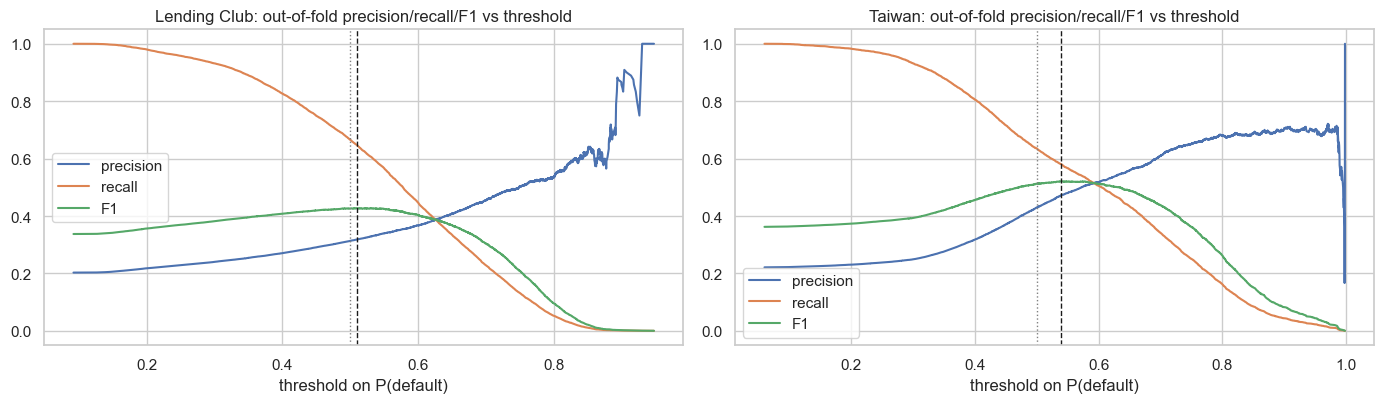

In [17]:
lr_final = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, (name, (Xa, Xb, ya, yb, num, cat)) in zip(axes, DATA.items()):
    est = best_lr[name].best_estimator_
    oof = cross_val_predict(est, Xa, ya, cv=CV5, method="predict_proba", n_jobs=-1)[:, 1]
    p, r, th = precision_recall_curve(ya, oof)
    f1s = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-9, None)
    thr = float(th[np.argmax(f1s)])
    prob = est.predict_proba(Xb)[:, 1]
    lr_final[name] = {"at 0.5": scores(yb, prob, 0.5), f"at tuned {thr:.3f}": scores(yb, prob, thr)}
    print(f"\n{name}: F1-optimal out-of-fold threshold = {thr:.3f}")
    display(pd.DataFrame(lr_final[name]).T.round(4))
    cm = confusion_matrix(yb, (prob >= thr).astype(int))
    print("Confusion matrix at tuned threshold [[TN FP] [FN TP]]:", cm.tolist())
    ax.plot(th, p[:-1], label="precision"); ax.plot(th, r[:-1], label="recall"); ax.plot(th, f1s, label="F1")
    ax.axvline(thr, color="k", ls="--", lw=1); ax.axvline(0.5, color="grey", ls=":", lw=1)
    ax.set_xlabel("threshold on P(default)"); ax.set_title(f"{name}: out-of-fold precision/recall/F1 vs threshold"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/fig_w4_threshold.png", dpi=150, bbox_inches="tight"); plt.show()

### Threshold-Tuning Findings

**Lending Club.**

* F1-optimal cutoff on out-of-fold predictions: 0.510.
* Test results at that cutoff: precision 0.324, recall 0.653, F1 **0.433**.
* At 0.5: precision 0.321, recall 0.678, F1 0.436.
* Confusion matrix at the tuned cutoff: TN 6,242, FP 3,323, FN 845, TP 1,590.

**Taiwan.**

* F1-optimal cutoff: 0.540.
* Test results: precision 0.463, recall 0.569, F1 **0.511**, accuracy 0.759. At 0.5, F1 is 0.501.
* Confusion matrix: TN 3,791, FP 876, FN 571, TP 755.

Three observations:

* **Balanced weights already move the optimum close to 0.5.** Once the classes are reweighted, the F1-optimal cutoff sits near 0.5, so threshold tuning adds little on Lending Club and about 1 F1 point on Taiwan. Reweighting and threshold tuning are two routes to the same goal; doing both (as here) shows that one is enough.
* **The Lending Club confusion matrix** says the model catches 1,590 of 2,435 defaults (65%) at the cost of declining 3,323 of 9,565 good borrowers (35%). That is the price of a 0.71 AUC ceiling.
* **Taiwan separates better** (AUC 0.741, PR-AUC 0.499 vs a 0.221 baseline), which is consistent with the strong `PAY_1` signal observed in the data-quality step.

In the plot, precision rises and recall falls as the threshold increases. F1 peaks in a broad plateau, so any cutoff between about 0.45 and 0.6 gives similar F1.

F1 is not necessarily the right business objective. A cost-weighted threshold (for example, missed default costs 5× a lost customer) would push the cutoff lower.

### 6. Taiwan — Feature Scaling (Unscaled vs StandardScaler) and Odds Ratios

Repeating the scaling experiment on Taiwan tests whether scaling matters when the raw numerics already live on comparable scales. Taiwan's numerics range from `PAY_1` (−2 to 8) to `log_LIMIT_BAL` (about 9 to 14), so the scale differences are much smaller than in raw Lending Club.

The odds ratios (e^β per 1 SD) of the scaled model show which features move default odds the most.

In [18]:
Xa, Xb, ya, yb, num, cat = DATA["Taiwan"]
tw_scale = {}
for label, sc in [("unscaled", False), ("standard", True)]:
    pipe = Pipeline([("prep", make_prep(num, cat, scale=sc)), ("clf", LogisticRegression(max_iter=1000))]).fit(Xa, ya)
    tw_scale[label] = {**scores(yb, pipe.predict_proba(Xb)[:, 1]), "n_iter": int(pipe.named_steps["clf"].n_iter_[0])}
    if sc: tw_std = pipe
display(pd.DataFrame(tw_scale).T.round(4))
names = tw_std.named_steps["prep"].get_feature_names_out()
orr = pd.DataFrame({"feature": names, "coef": tw_std.named_steps["clf"].coef_[0]})
orr["odds_ratio"] = np.exp(orr["coef"])
display(orr.reindex(orr["coef"].abs().sort_values(ascending=False).index).head(8).round(4))

,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold,n_iter
unscaled,0.8074,0.6777,0.2474,0.3624,0.7402,0.5072,0.5,554.0
standard,0.8078,0.6783,0.2496,0.3649,0.7401,0.5073,0.5,31.0


,feature,coef,odds_ratio
23,cat__EDUCATION_4,-1.0226,0.3597
2,num__PAY_1,0.5154,1.6744
25,cat__MARRIAGE_3,-0.2083,0.8119
24,cat__MARRIAGE_2,-0.1820,0.8336
14,num__log_PAY_AMT1,-0.1623,0.8502
16,num__log_PAY_AMT3,-0.1595,0.8525
15,num__log_PAY_AMT2,-0.1592,0.8529
0,num__log_LIMIT_BAL,-0.1310,0.8772


### Taiwan Scaling and Odds-Ratio Findings

* **Unscaled:** 554 iterations, AUC 0.7402.
* **Standardized:** 31 iterations, AUC 0.7401, with every other metric within 0.003.

The largest effects (standardized model):

* `EDUCATION_4` ("other") OR 0.36
* **`PAY_1` OR 1.67 per SD** (+1 SD ≈ +1.1 months of delay)
* `MARRIAGE_3` 0.81
* `log_PAY_AMT1–3` about 0.85 each
* `log_LIMIT_BAL` 0.88

Scaling changes optimization speed, not accuracy. It sped convergence 18× (554 → 31 iterations), matching the Lending Club pattern (1,000+ → 55) seen in Part B. With L2 regularization, scaling also determines *which* coefficients get penalized, but that only matters when the penalty is strong.

Payment history dominates Taiwan risk. The latest month's delay status raises the odds of default by about 67% per standard deviation. Clients who paid more in recent months and clients with higher credit limits (which the bank assigned to lower-risk customers) have lower odds of defaulting.

The `EDUCATION_4` odds ratio is unreliable because it rests on only 468 recoded clients, so it is imprecise and should not be read as a real education effect.

The high `log_LIMIT_BAL` odds ratio should not be read causally. A higher credit limit does not *cause* lower default; the bank assigned high limits to clients it already judged to be safe.

### 7. Analysis Summary Table

The per-dataset best model (parameters from the CV grid search) is scored at both the default 0.5 threshold and the F1-tuned threshold, so the gap between the two cutoffs can be read in one table.

In [19]:
summ = []
for name in DATA:
    for k, v in lr_final[name].items():
        summ.append({"dataset": name, "model": f"LogReg {best_lr[name].best_params_}", "rule": k, **v})
w4_summary = pd.DataFrame(summ)
display(w4_summary.round(4))

,dataset,model,rule,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold
0,Lending Club,"LogReg {'clf__C': 1, 'clf__penalty': 'l1'}",at 0.5,0.6438,0.3212,0.6784,0.4359,0.7126,0.3782,0.5000
1,Lending Club,"LogReg {'clf__C': 1, 'clf__penalty': 'l1'}",at tuned 0.510,0.6527,0.3236,0.6530,0.4328,0.7126,0.3782,0.5098
2,Taiwan,"LogReg {'clf__C': 0.001, 'clf__penalty': 'l2'}",at 0.5,0.7272,0.4207,0.6184,0.5008,0.7410,0.4993,0.5000
3,Taiwan,"LogReg {'clf__C': 0.001, 'clf__penalty': 'l2'}",at tuned 0.540,0.7586,0.4629,0.5694,0.5107,0.7410,0.4993,0.5396


## 8. Conclusion

The best tuned logistic regression on each dataset gives:

* **Lending Club:** ROC-AUC 0.713, PR-AUC 0.378, F1 of 0.43–0.44, recall 0.65–0.68.
* **Taiwan:** ROC-AUC 0.741, PR-AUC 0.499, F1 of 0.50–0.51.

Three findings carry the analysis.

**Class weighting fixed the problem, not CV tuning.** Setting `class_weight="balanced"` moved Lending Club recall from 0.05 to 0.68 and quadrupled F1 (0.11 → 0.44). Tuning `C` and the penalty barely mattered — the CV AUC surface was flat enough that the differences between candidates fell inside one standard deviation of the folds.

**Feature scaling is about convergence, not accuracy.** StandardScaler sped Lending Club training by about 18× and Taiwan training by about 18× as well, while leaving ROC-AUC and PR-AUC essentially unchanged. With regularization, scaling also determines which coefficients get penalized, but only strong penalties make that visible, and the preferred penalty strengths here were mild.

**Threshold tuning adds little once the classes are already reweighted.** On Lending Club the F1-optimal cutoff was 0.510 (versus the 0.5 default) and on Taiwan it was 0.540. On a precision-recall curve, the F1 peak is a plateau rather than a sharp maximum, so any cutoff between roughly 0.45 and 0.60 gives similar F1.

### Key Limitations

The results describe associations within fitted logistic models and are not causal. Odds ratios such as `log_LIMIT_BAL` or `EDUCATION_4` reflect how the bank chose to assign credit limits and how the "other" education bucket was constructed, not an independent effect of those variables on default risk.

F1 is not the only reasonable objective. A proper cost-weighted rule — for example, missed default costs 5× a declined good customer — would move the preferred cutoff lower than the F1-optimal choice.

Overall, the practical takeaway is that logistic regression here is a well-calibrated **ranker** (ROC-AUC in the low 0.7s) rather than a confident classifier, and the decision rule (threshold + class weighting) does more to shape the usable precision/recall mix than the regularization choice.